In [161]:
import pandas as pd
import numpy as np
from IPython.display import display
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

In [162]:
data = pd.read_csv('datos.csv')

In [163]:
t = data['t'].values
#Abundancia de ciervos
x = data['ciervos'].values.astype(float) 
#Abundancia de chanchos
y = data['chanchos'].values.astype(float)

### **Excercise 1**

In [164]:
ln_x = np.log(x)
ln_y = np.log(y)

dt = np.diff(t)
dln_x = np.diff(ln_x)
dln_y = np.diff(ln_y)

In [165]:
# MID POINT SCHEME
def numerical_derivate(x_sub, y_sub, t_sub):
    N = len(t_sub)
    gx, gy = [], []
    xk_plus_half, yk_plus_half, tk_plus_half = [], [], []

    for k in range(N - 1):
        xk, xk1 = x_sub[k], x_sub[k+1]
        yk, yk1 = y_sub[k], y_sub[k+1]
        tk, tk1 = t_sub[k], t_sub[k+1]
        dtk = tk1 - tk

        # Log derivate 
        gx_k = (np.log(xk1) - np.log(xk)) / dtk
        gy_k = (np.log(yk1) - np.log(yk)) / dtk

        #Regressors evaluated in the midpoint
        xk_mid= (xk + xk1) / 2
        yk_mid = (yk + yk1) / 2
        tk_mid = (tk + tk1) / 2

        gx.append(gx_k)
        gy.append(gy_k)
        xk_plus_half.append(xk_mid)
        yk_plus_half.append(yk_mid)
        tk_plus_half.append(tk_mid)

    #Convert to numpy array
    gx = np.array(gx)
    gy = np.array(gy)
    xk_plus_half = np.array(xk_plus_half)
    yk_plus_half = np.array(yk_plus_half)
    tk_plus_half = np.array(tk_plus_half)

    return gx, gy, xk_plus_half, yk_plus_half, tk_plus_half


In [166]:
#Compute the A matrix -> [a11, b12, b22]
def solve(gx, gy, xk_plus_half, yk_plus_half):
    A = np.column_stack([np.ones_like(xk_plus_half), -xk_plus_half, -yk_plus_half])
    theta_x, *_ = np.linalg.lstsq(A, gx, rcond = None)
    theta_y, *_ = np.linalg.lstsq(A, gy, rcond = None)

    residual_x = A @ theta_x - gx
    residual_y = A @ theta_y - gy

    return theta_x, theta_y, residual_x, residual_y

In [167]:
#dt = 1
gx_dt1, gy_dt1, xk_plus_half_dt1, yk_plus_half_dt1, tk_plus_half_dt1 = numerical_derivate(x, y,t)

In [168]:
theta_x_1, theta_y_1, residual_x1, residual_y1 = solve(gx_dt1, gy_dt1, xk_plus_half_dt1, yk_plus_half_dt1)

a1, b11, b12 = theta_x_1
a2, b21, b22 = theta_y_1

print("dt = 1 (1-year gap analysis)")
print(f"a1 = {a1:.4f}, \nb11 = {b11:.4f}, \nb12 = {b12:.4f}")
print(f"a2 = {a2:.4f}, \nb21 = {b21:.4f}, \nb22 = {b22:.4f}")

dt = 1 (1-year gap analysis)
a1 = 0.4503, 
b11 = 0.0002, 
b12 = 0.0004
a2 = 0.6377, 
b21 = 0.0003, 
b22 = 0.0007


#### **1.2**

In [169]:
#dt = 2
x_2, y_2, t_2 = x[::2], y[::2], t[::2]
gx_dt2, gy_dt2, xk_plus_half_dt2, yk_plus_half_dt2, tk_plus_half_dt2 = numerical_derivate(x_2, y_2, t_2)

In [170]:
theta_x_2, theta_y_2, residual_x2, residual_y2 = solve(gx_dt2, gy_dt2, xk_plus_half_dt2, yk_plus_half_dt2)

a1_dt2, b11_dt2, b12_dt2 = theta_x_2
a2_dt2, b21_dt2, b22_dt2 = theta_y_2

print("dt = 2 (2-year gap analysis)")
print(f"a1 = {a1_dt2:.4f}, \nb11 = {b11_dt2:.4f}, \nb12 = {b12_dt2:.4f}")
print(f"a2 = {a2_dt2:.4f}, \nb21 = {b21_dt2:.4f}, \nb22 = {b22_dt2:.4f}")

dt = 2 (2-year gap analysis)
a1 = 0.5051, 
b11 = 0.0002, 
b12 = 0.0005
a2 = 0.7046, 
b21 = 0.0002, 
b22 = 0.0008


#### **1.3**

<p style="text-align: justify; text-justify: inter-word; font-size: 16px;">
<i>a<sub>1</sub></i>: growth rate of the deer population when alone — how much the population grows per year, in relative terms, if there were nothing to hold it back.
</p>

<p style="text-align: justify; text-justify: inter-word; font-size: 16px;">
<i>a<sub>2</sub></i>: growth rate of the boar population when alone — how much the population grows per year, in relative terms, if there were nothing to hold it back.
</p>

<p style="text-align: justify; text-justify: inter-word; font-size: 16px;">
<i>b<sub>11</sub></i>: how much the deer population holds back its own growth as $x$ increases (intraspecific competition — deer competing among themselves for the same resources). This is what keeps the population from growing forever.
</p>

<p style="text-align: justify; text-justify: inter-word; font-size: 16px;">
<i>b<sub>22</sub></i>: how much the boar population holds back its own growth as $y$ increases (intraspecific competition — individuals competing among themselves for the same resources).
</p>

<p style="text-align: justify; text-justify: inter-word; font-size: 16px;">
<i>b<sub>12</sub></i>: how much the boar population holds back the deer (interspecific competition — an extra boar takes resources away from the deer).
</p>

<p style="text-align: justify; text-justify: inter-word; font-size: 16px;">
<i>b<sub>21</sub></i>: how much the deer population holds back the boar (the other way around).
</p>


In [171]:
K1 = a1 / b11
K2 = a2 / b22

alpha12 = b12 / b11
alpha21 = b21 / b22

<p style="text-align: justify; text-justify: inter-word; font-size: 16px;">
We fit $a_1, b_{11}, b_{12}, a_2, b_{21}, b_{22}$ from 32 points, with no simple closed-form uncertainty formula (the regression uses a numerically estimated derivative with lognormal noise, so the "least squares with normal errors" formulas don't apply). The bootstrap sidesteps that: it resamples the 32 rows of $A\theta\approx g$ with replacement, re-solves the same least squares 200 times, and the spread across those 200 replicas becomes the "95% CI" column in your table.
</p>

In [ ]:
# Bootstraping
n_boot = 200
n_data = len(gx_dt1)

boot_theta_x = np.zeros((n_boot, 3))
boot_theta_y = np.zeros((n_boot, 3))

# Fixed seed to assure reproducibility
rng = np.random.default_rng(42)

for i in range(n_boot):
    # Resample row indices with replacement
    idx = rng.integers(0, n_data, size = n_data)

    # Resample data
    gx_boot = gx_dt1[idx]
    gy_boot = gy_dt1[idx]
    x_mid_bootstrap = xk_plus_half_dt1[idx]
    y_mid_bootstrap = yk_plus_half_dt1[idx]

    tx,ty, _, _ = solve(gx_boot, gy_boot, x_mid_bootstrap, y_mid_bootstrap)

    # Store this replicate's [a1, b11, b12]
    boot_theta_x[i] = tx
    # Store this replicate's [a2, b21, b22]
    boot_theta_y[i] = ty

In [173]:
boot_K1 = boot_theta_x[:,0] / boot_theta_x[:,1]       
boot_K2 = boot_theta_y[:,0] / boot_theta_y[:,2]      
boot_alpha12 = boot_theta_x[:,2] / boot_theta_x[:,1]   
boot_alpha21 = boot_theta_y[:,1] / boot_theta_y[:,2]  

boot_all = {
    "a1": boot_theta_x[:,0], "b11": boot_theta_x[:,1], "b12": boot_theta_x[:,2],
    "a2": boot_theta_y[:,0], "b21": boot_theta_y[:,1], ""
    "b22": boot_theta_y[:,2],
    "K1": boot_K1, "K2": boot_K2, "alpha12": boot_alpha12, "alpha21": boot_alpha21,
}

In [174]:
df = pd.DataFrame({
    "Parameter": ["a1", "b11", "b12", "a2", "b21", "b22", "K1", "K2", "alpha12", "alpha21"],
    "Unit": ["1/year", "1/year per individual", "1/year per individual",
               "1/year", "1/year per individual", "1/year per individual",
               "individual", "individual", "adimensional", "adimensional"],
    "Estimation": [a1, b11, b12, a2, b21, b22, K1, K2, alpha12, alpha21],
})

df["IC 95%"] = [
    f"[{np.percentile(boot_all[p], 2.5):.4g}, {np.percentile(boot_all[p], 97.5):.4g}]"
    for p in df["Parameter"]
]

display(df)

,Parameter,Unit,Estimation,IC 95%
0,a1,1/year,0.450286,"[-0.06959, 0.5628]"
1,b11,1/year per individual,0.000235,"[7.278e-05, 0.0003199]"
2,b12,1/year per individual,0.000393,"[-0.0002416, 0.000603]"
3,a2,1/year,0.637679,"[0.298, 0.9966]"
4,b21,1/year per individual,0.000255,"[0.0001163, 0.0004108]"
5,b22,1/year per individual,0.000702,"[0.0002904, 0.00116]"
6,K1,individual,1913.892163,"[-768.7, 2821]"
7,K2,individual,908.816630,"[795.7, 1119]"
8,alpha12,adimensional,1.668348,"[-2.65, 3.102]"
9,alpha21,adimensional,0.363443,"[0.1842, 0.6623]"


In [175]:
# Verificación: las dos parametrizaciones dan el mismo resultado
x_test, y_test = 840, 653   # cualquier punto, por ejemplo el estado de 2024

# Forma (1): con a1, b11, b12
dx_forma1 = x_test * (a1 - b11*x_test - b12*y_test)
dy_forma1 = y_test * (a2 - b21*x_test - b22*y_test)

# Forma (2): con r1=a1, K1, alpha12
r1, r2 = a1, a2   # r1=a1, r2=a2, por la Consigna 0
dx_forma2 = r1 * x_test * (1 - (x_test + alpha12*y_test)/K1)
dy_forma2 = r2 * y_test * (1 - (y_test + alpha21*x_test)/K2)

print(f"dx: forma (1) = {dx_forma1:.4f}, forma (2) = {dx_forma2:.4f}")
print(f"dy: forma (1) = {dy_forma1:.4f}, forma (2) = {dy_forma2:.4f}")


dx: forma (1) = -3.0710, forma (2) = -3.0710
dy: forma (1) = -22.6687, forma (2) = -22.6687


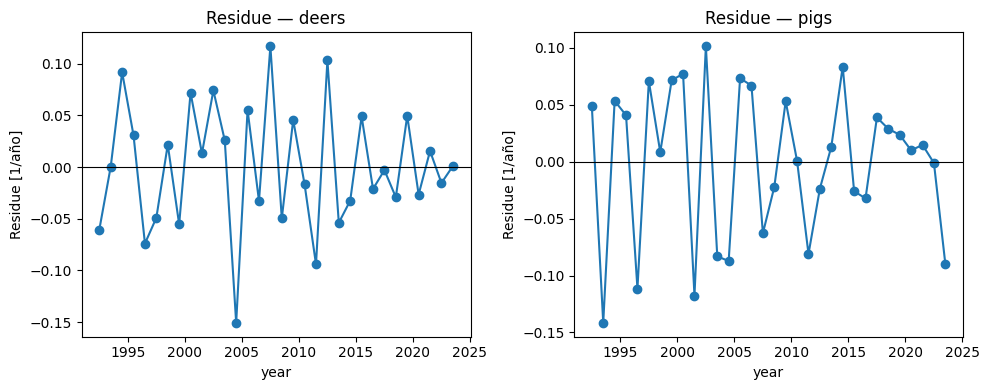

In [176]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4))

axs[0].plot(tk_plus_half_dt1, residual_x1, 'o-')
axs[0].axhline(0, color='k', lw=0.8)
axs[0].set_xlabel("year")
axs[0].set_ylabel("Residue [1/año]")
axs[0].set_title("Residue — deers")

axs[1].plot(tk_plus_half_dt1, residual_y1, 'o-')
axs[1].axhline(0, color='k', lw=0.8)
axs[1].set_xlabel("year")
axs[1].set_ylabel("Residue [1/año]")
axs[1].set_title("Residue — pigs")

plt.tight_layout()
plt.savefig("residues.png", dpi=150, bbox_inches="tight")
plt.show()

#### **1.4**

In [177]:
#Separate between train and test
mask_train = t <= 2012
X_train, Y_train, T_train = x[mask_train], y[mask_train], t[mask_train]

mask_test = t > 2012
X_test, Y_test, T_test = x[mask_test], y[mask_test], t[mask_test]

In [178]:
#Adjust just using the train set
gx_train, gy_train, xk_plus_half_train, yk_plus_half_train, tk_plus_half_train = numerical_derivate(X_train, Y_train, T_train)
theta_x_train, theta_y_train, residual_x_train, residual_y_train = solve(gx_train, gy_train, xk_plus_half_train, yk_plus_half_train)

a1_train, b11_train, b12_train = theta_x_train
a2_train, b21_train, b22_train = theta_y_train
print('Learned parameters using the data from the 1992-2012 period -> ', theta_x_train, theta_y_train)

Learned parameters using the data from the 1992-2012 period ->  [4.48010583e-01 2.10865802e-04 4.01531574e-04] [6.50833131e-01 2.27243824e-04 7.34649912e-04]


In [179]:
# x= x(a1−b11 x−b12 y),
# y= y(a2−b21 x−b22 y)

def lotka_volterra(tm, z, a1, b11, b12, a2, b21, b22):
    x, y = z
    dxdt = x * (a1 - b11 * x - b12 * y)
    dydt = y * (a2 - b21 * x - b22 * y)
    return np.array([dxdt, dydt])

In [180]:
index_year_2012 = np.where(t == 2012)[0][0]
# Initial conditions for the ODE solver
z0 = [x[index_year_2012], y[index_year_2012]]  

solution = solve_ivp(lotka_volterra, [2012, 2024], z0, args = (a1_train, b11_train, b12_train, a2_train, b21_train, b22_train), dense_output = True, max_step = 0.1)

# Evaluate the solution at the test time points
prediction = solution.sol(T_test)
pred_x, pred_y = prediction[0], prediction[1]

In [181]:
# Relative mean error
error_x = np.abs((pred_x - X_test) / X_test)
error_y = np.abs((pred_y - Y_test) / Y_test)

print(f"Relative mean error for deer population prediction: {np.mean(error_x):.4f}")
print(f"Relative mean error for pig population prediction: {np.mean(error_y):.4f}")

Relative mean error for deer population prediction: 0.0321
Relative mean error for pig population prediction: 0.0389


### **Excercise 2**

nternal equilibrium: obtaining $x$ and $y$

To compute the internal equilibrium, we need 2 conditions: $\dot x=0$ and $\dot y=0$. With this, we divide each of the equations in (1) by $x$ and $y$ respectively, obtaining the following 2x2 system:

$$b_{11}x + b_{12}y = a_1 \qquad \text{(I)}$$
$$b_{21}x + b_{22}y = a_2 \qquad \text{(II)}$$

Solving for $x^*$ (eliminating $y$):

Multiplying (I) by $b_{22}$ and (II) by $b_{12}$, the $y$ terms become equal:

$$b_{22}\cdot\text{(I)}:\quad b_{11}b_{22},x + b_{12}b_{22},y = a_1 b_{22}$$
$$b_{12}\cdot\text{(II)}:\quad b_{21}b_{12},x + b_{22}b_{12},y = a_2 b_{12}$$

Subtracting the two equations, the $y$ term cancels out:

$$(b_{11}b_{22}-b_{12}b_{21}),x = a_1 b_{22} - a_2 b_{12}$$

Defining $\det = b_{11}b_{22}-b_{12}b_{21}$:

$$x^* = \frac{a_1 b_{22} - a_2 b_{12}}{\det}$$

Solving for $y^*$ (eliminating $x$):

Multiplying (I) by $b_{21}$ and (II) by $b_{11}$, the $x$ terms become equal:

$$b_{21}\cdot\text{(I)}:\quad b_{11}b_{21},x + b_{12}b_{21},y = a_1 b_{21}$$
$$b_{11}\cdot\text{(II)}:\quad b_{11}b_{21},x + b_{11}b_{22},y = a_2 b_{11}$$

Subtracting, the $x$ term cancels out:

$$(b_{11}b_{22}-b_{12}b_{21}),y = a_2 b_{11} - a_1 b_{21}$$

$$y^* = \frac{a_2 b_{11} - a_1 b_{21}}{\det}$$

The same $\det$ appears in both expressions because it is the determinant of the coefficient matrix $\begin{pmatrix}b_{11}&b_{12}\\b_{21}&b_{22}\end{pmatrix}$

In [182]:
eq1 = (0,0)
eq2 = (K1, 0)
eq3 = (0, K2)

# Internal 
det = b11 * b22 - b12 * b21
x_star = (a1 * b22 - a2 * b12) / det
y_star = (a2 * b11 - a1 * b21) / det
eq4 = (x_star, y_star)


equilibriums = pd.DataFrame({
    "Equilibrium": ["(0,0)", "(K1,0)", "(0,K2)", "internal (x*,y*)"],
    "x [individuals]": [0, K1, 0, x_star],
    "y [individuals]": [0, 0, K2, y_star],
})

display(equilibriums.style.format({"x [individuals]": "{:.4f}", "y [individuals]": "{:.4f}",
}))


,Equilibrium,x [individuals],y [individuals]
0,"(0,0)",0.0000,0.0000
1,"(K1,0)",1913.8922,0.0000
2,"(0,K2)",0.0000,908.8166
3,"internal (x*,y*)",1010.2081,541.6639


##### **Check if by 2024 the system has already reached the equilibrium**

In [183]:
index_2024 = np.where(t == 2024)[0][0]
z0_24 = [x[index_2024], y[index_2024]]

In [184]:
solution_2060 = solve_ivp(lotka_volterra, [2024, 2060], z0_24, args = (a1, b11, b12, a2, b21, b22), dense_output = True, max_step = 0.1)

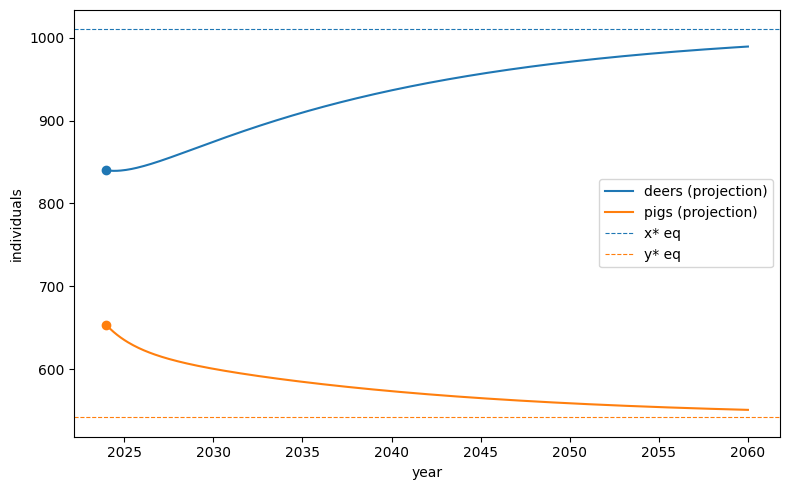

In [185]:
t_linspace = np.linspace(2024, 2060, 360)
trajectory = solution_2060.sol(t_linspace)

fig, ax = plt.subplots(figsize=(8,5))
ax.plot(t_linspace, trajectory[0], label = "deers (projection)")
ax.plot(t_linspace, trajectory[1], label = "pigs (projection)")
ax.axhline(x_star, ls = '--', color='C0', lw = 0.8, label = "x* eq")
ax.axhline(y_star, ls = '--', color='C1', lw = 0.8, label = "y* eq")
ax.scatter([2024], [z0_24[0]], color = 'C0', zorder=5)
ax.scatter([2024], [z0_24[1]], color = 'C1', zorder = 5)
ax.set_xlabel("year")
ax.set_ylabel("individuals")
ax.legend()
plt.tight_layout()
plt.savefig("projections.png", dpi=150, bbox_inches="tight")
plt.show()

In [186]:
estado_2060 = solution_2060.sol(2060)
print(f"Real state by 2024:       x = {z0_24[0]:.0f}, y = {z0_24[1]:.0f}")
print(f"Projected state by 2060:  x = {estado_2060[0]:.0f}, y = {estado_2060[1]:.0f}")
print(f"Internal equilibrium:     x* = {x_star:.0f}, y* = {y_star:.0f}")

dist_2024 = np.hypot(z0_24[0] - x_star, z0_24[1] - y_star)
print(f"\n2024's distance to the equilibrium: {dist_2024:.1f} individuals")

Real state by 2024:       x = 840, y = 653
Projected state by 2060:  x = 989, y = 551
Internal equilibrium:     x* = 1010, y* = 542

2024's distance to the equilibrium: 203.4 individuals


### **Excercise 3**

In [187]:
def controlled_lotka_volterra(tm, z, k):
    #x = poblacion ciervos, y = poblacion chanchos
    x, y = z
    u = k * y
    dxdt = x * (a1 - b11 * x - b12 * y)
    dydt = y * (a2 - b21 * x - b22 * y) - u
    return np.array([dxdt, dydt])

##### **Simulation**

In [188]:
k_list = [0, 0.1, 0.2, 0.4]
t_list = np.linspace(0, 40, 400)

results = {}
for k in k_list:
    solution = solve_ivp(controlled_lotka_volterra, [0, 40], z0_24, args = (k, ), dense_output = True, max_step = 0.5, t_eval = t_list)
    results[k] = solution

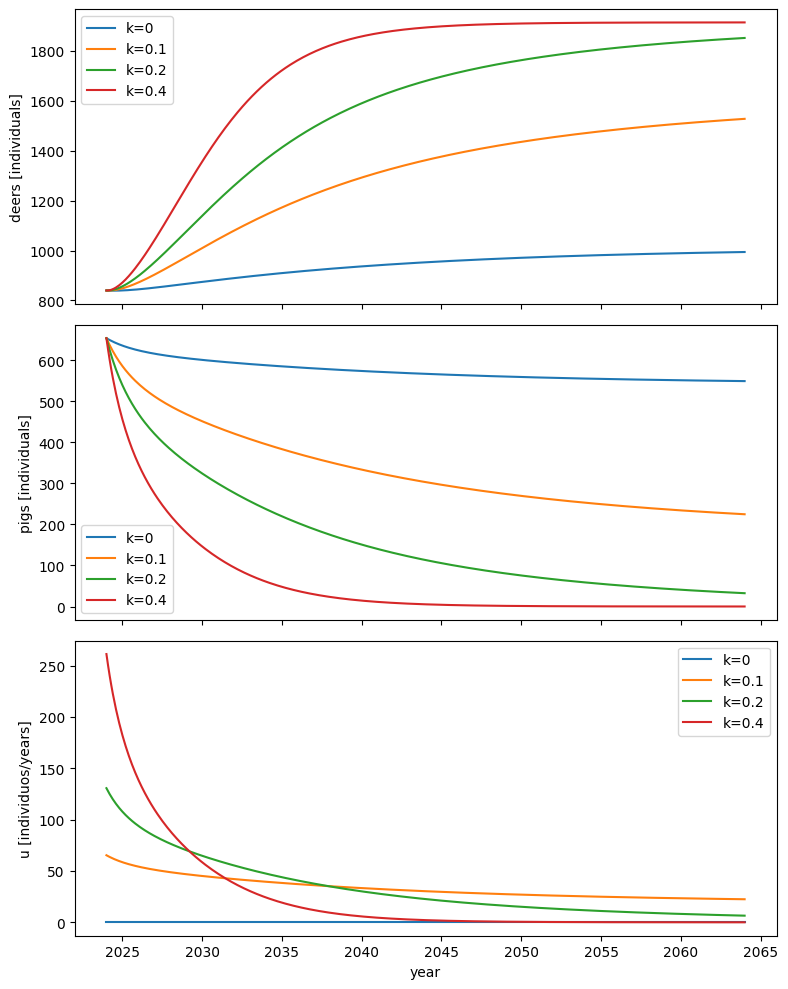

In [189]:
fig, axs = plt.subplots(3, 1, figsize=(8, 10), sharex=True)

for k in k_list:
    sol = results[k]
    u_t = k * sol.y[1]         

    axs[0].plot(2024 + sol.t, sol.y[0], label=f"k={k}")
    axs[1].plot(2024 + sol.t, sol.y[1], label=f"k={k}")
    axs[2].plot(2024 + sol.t, u_t, label=f"k={k}")

axs[0].set_ylabel("deers [individuals]")
axs[1].set_ylabel("pigs [individuals]")
axs[2].set_ylabel("u [individuos/years]")
axs[2].set_xlabel("year")

for a in axs:
    a.legend()
plt.tight_layout()
plt.savefig("simulations.png", dpi=150, bbox_inches="tight")
plt.show()


In [190]:
for k in k_list:
    solution = results[k]
    u_t = k * solution.y[1]

    extracted = np.trapezoid(u_t, solution.t)
    print(f'k = {k} -> number of extracted animals in 40 years = {extracted:.0f}')

k = 0 -> number of extracted animals in 40 years = 0
k = 0.1 -> number of extracted animals in 40 years = 1340
k = 0.2 -> number of extracted animals in 40 years = 1336
k = 0.4 -> number of extracted animals in 40 years = 1001


##### **Saturation**

In [191]:
u_max = 120

In [192]:
def satured_lotka_volterra(tm, z, k):
    x, y = z
    u = min(u_max, k * y)
    dxdt = x * (a1 - b11 * x - b12 * y)
    dydt = y * (a2 - b21 * x - b22 * y) - u
    return np.array([dxdt, dydt])

In [193]:
results_saturation = {}
for k in k_list:
    solution = solve_ivp(satured_lotka_volterra, [0, 40], z0_24, args = (k, ), dense_output = True, max_step = 0.5, t_eval = t_list)
    results_saturation[k] = solution

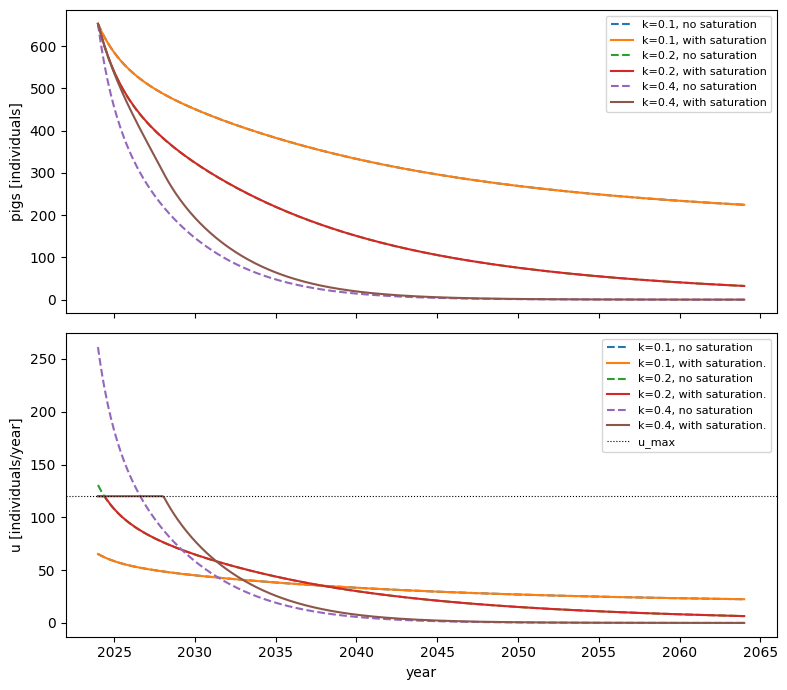

In [194]:
fig, axs = plt.subplots(2, 1, figsize=(8, 7), sharex=True)

for k in [0.1, 0.2, 0.4]:
    sol_sin = results[k]       
    sol_con = results_saturation[k]   

    axs[0].plot(2024 + sol_sin.t, sol_sin.y[1], '--', label=f"k={k}, no saturation")
    axs[0].plot(2024 + sol_con.t, sol_con.y[1], '-', label=f"k={k}, with saturation")

    u_sin = k * sol_sin.y[1]
    u_con = np.minimum(u_max, k * sol_con.y[1])
    axs[1].plot(2024 + sol_sin.t, u_sin, '--', label=f"k={k}, no saturation")
    axs[1].plot(2024 + sol_con.t, u_con, '-', label=f"k={k}, with saturation.")

axs[1].axhline(u_max, color='k', lw=0.8, ls=':', label="u_max")
axs[0].set_ylabel("pigs [individuals]")
axs[1].set_ylabel("u [individuals/year]")
axs[1].set_xlabel("year")
axs[0].legend(fontsize=8); axs[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig("saturation.png", dpi=150, bbox_inches="tight")
plt.show()


In [195]:
for k in [0.1, 0.2, 0.4]:
    sol_no_sat, sol_sat = results[k], results_saturation[k] 
    final_no_sat = sol_no_sat.y[:, -1]
    final_sat = sol_sat.y[:, -1]

    u_sat = np.minimum(u_max, k * sol_sat.y[1])
    total_sat = np.trapezoid(u_sat, sol_sat.t)

    print(f'\nk = {k}:') 
    print(f'Final state NO saturation -> x = {final_no_sat[0]:.0f}, y = {final_no_sat[1]:.1f}')
    print(f'Final state WITH saturation -> x = {final_sat[0]:.0f}, y = {final_sat[1]:.1f}')
    print(f'Extracted with saturation = {total_sat:.0f}')



k = 0.1:
Final state NO saturation -> x = 1528, y = 224.6
Final state WITH saturation -> x = 1528, y = 224.6
Extracted with saturation = 1340

k = 0.2:
Final state NO saturation -> x = 1851, y = 32.4
Final state WITH saturation -> x = 1851, y = 32.4
Extracted with saturation = 1336

k = 0.4:
Final state NO saturation -> x = 1914, y = 0.0
Final state WITH saturation -> x = 1914, y = 0.0
Extracted with saturation = 1019


##### **Threshold policy**

In [196]:
y_ref = 150

In [197]:
def threshold_lotka_volterra(tm, z, k):
    x, y = z
    u = min(u_max, k * max(0, y - y_ref))
    dxdt = x * (a1 - b11 * x - b12 * y)
    dydt = y * (a2 - b21 * x - b22 * y) - u
    return np.array([dxdt, dydt])

In [198]:
results_threshold_policy = {}
for k in [0.3, 0.5, 1.0, 2.0]:
    solution = solve_ivp(threshold_lotka_volterra, [0, 40], z0_24, args = (k, ), dense_output = True, max_step = 0.5, t_eval = t_list)
    results_threshold_policy[k] = solution

    y_final = solution.y[1, -1]
    error_regimen = y_final - y_ref
    print(f'k = {k} -> y_final = {y_final:.1f}, error regimen = {error_regimen:+.1f}')

k = 0.3 -> y_final = 215.0, error regimen = +65.0
k = 0.5 -> y_final = 186.6, error regimen = +36.6
k = 1.0 -> y_final = 167.3, error regimen = +17.3
k = 2.0 -> y_final = 158.4, error regimen = +8.4


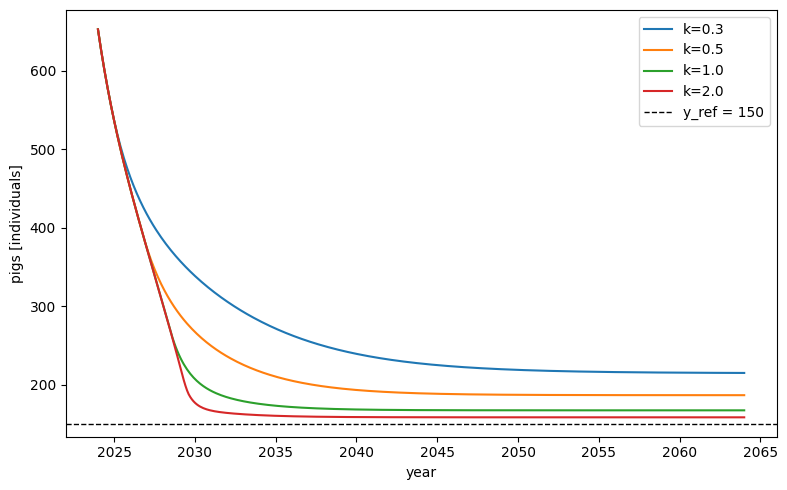

In [199]:
fig, ax = plt.subplots(figsize=(8,5))

for k in [0.3, 0.5, 1.0, 2.0]:
    sol = results_threshold_policy[k]
    ax.plot(2024 + sol.t, sol.y[1], label=f"k={k}")
ax.axhline(y_ref, color='k', ls='--', lw=1, label="y_ref = 150")
ax.set_xlabel("year"); ax.set_ylabel("pigs [individuals]")
ax.legend()
plt.tight_layout()
plt.savefig("threshold.png", dpi=150, bbox_inches="tight")
plt.show()


In [200]:
x_no_control = results[0].y[0, -1]
print(f'Deers with no control (40 years) = {x_no_control:.0f}')

print('\n--- SCENERY 3.1 (no saturation) ---')
for k in k_list:
    x_f = results[k].y[0, -1]
    print(f'k = {k} -> deers = {x_f:.0f} ({100 * (x_f / x_no_control - 1):+.0f}% vs no control)')

print('\n--- SCENERY 3.2 (saturation - y_ref = 120) ---')
for k in k_list:
    x_saturation = results_saturation[k].y[0, -1]
    print(f'k = {k} -> deers = {x_saturation:.0f} ({100 * (x_saturation / x_no_control - 1):+.0f}% vs no control)')

print('\n--- SCENERY 3.3 (threshold policy - y_ref = 150) ---')
for k in [0.3, 0.5, 1.0, 2.0]:
    x_threshold = results_threshold_policy[k].y[0, -1]
    print(f'k = {k} -> deers = {x_threshold:.0f} ({100 * (x_threshold / x_no_control - 1):+.0f}% vs no control)')

Deers with no control (40 years) = 994

--- SCENERY 3.1 (no saturation) ---
k = 0 -> deers = 994 (+0% vs no control)
k = 0.1 -> deers = 1528 (+54% vs no control)
k = 0.2 -> deers = 1851 (+86% vs no control)
k = 0.4 -> deers = 1914 (+92% vs no control)

--- SCENERY 3.2 (saturation - y_ref = 120) ---
k = 0 -> deers = 994 (+0% vs no control)
k = 0.1 -> deers = 1528 (+54% vs no control)
k = 0.2 -> deers = 1851 (+86% vs no control)
k = 0.4 -> deers = 1914 (+92% vs no control)

--- SCENERY 3.3 (threshold policy - y_ref = 150) ---
k = 0.3 -> deers = 1555 (+56% vs no control)
k = 0.5 -> deers = 1603 (+61% vs no control)
k = 1.0 -> deers = 1635 (+64% vs no control)
k = 2.0 -> deers = 1650 (+66% vs no control)
